<a href="https://colab.research.google.com/github/04231073/Smart_City_MultiZone_Load_Forecasting/blob/main/Model_B__GA_%2B_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset

# Set device (GPU/CPU) & random seed agar hasil stabil
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
print(f"Menggunakan device: {device}")

Menggunakan device: cpu


In [ ]:
# 1. Load Dataset
df = pd.read_csv('Tetuan City power consumption.csv')
df.columns = df.columns.str.strip() # Hapus spasi ganda pada nama kolom

# 2. Feature Engineering DateTime
df['DateTime'] = pd.to_datetime(df['DateTime'])
df['Hour'] = df['DateTime'].dt.hour
df['DayOfWeek'] = df['DateTime'].dt.dayofweek
df['Month'] = df['DateTime'].dt.month

# Cyclical Encoding untuk Fitur Waktu
df['Hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24.0)
df['Hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24.0)

print("Fitur DateTime berhasil diolah. 5 data pertama:")
df[['DateTime', 'Hour_sin', 'Hour_cos', 'DayOfWeek', 'Month']].head()

Fitur DateTime berhasil diolah. 5 data pertama:


,DateTime,Hour_sin,Hour_cos,DayOfWeek,Month
0,2017-01-01 00:00:00,0.0,1.0,6,1
1,2017-01-01 00:10:00,0.0,1.0,6,1
2,2017-01-01 00:20:00,0.0,1.0,6,1
3,2017-01-01 00:30:00,0.0,1.0,6,1
4,2017-01-01 00:40:00,0.0,1.0,6,1


In [ ]:
import time
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Tentukan Kolom Fitur Dasar (9 Fitur) dan Target (3 Zona)
feature_cols = [
    'Temperature', 'Humidity', 'Wind Speed',
    'general diffuse flows', 'diffuse flows',
    'Hour_sin', 'Hour_cos', 'DayOfWeek', 'Month'
]
target_cols = [
    'Zone 1 Power Consumption',
    'Zone 2  Power Consumption',
    'Zone 3  Power Consumption'
]

# Protokol Split Kronologis Tetap: 70% Train, 15% Validation, 15% Test
n_total = len(df)
train_end = int(n_total * 0.70)
val_end = int(n_total * 0.85)

# Fit scaler HANYA pada data Train agar tidak terjadi data leakage
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_raw = scaler_X.fit_transform(df[feature_cols].iloc[:train_end].values)
X_val_raw   = scaler_X.transform(df[feature_cols].iloc[train_end:val_end].values)
X_test_raw  = scaler_X.transform(df[feature_cols].iloc[val_end:].values)

y_train_raw = scaler_y.fit_transform(df[target_cols].iloc[:train_end].values)
y_val_raw   = scaler_y.transform(df[target_cols].iloc[train_end:val_end].values)
y_test_raw  = scaler_y.transform(df[target_cols].iloc[val_end:].values)

# Fungsi Sliding Window (144 langkah = 24 jam)
def create_sequences(X, y, seq_length=144):
    X_seq, y_seq = [], []
    for i in range(len(X) - seq_length):
        X_seq.append(X[i : i + seq_length])
        y_seq.append(y[i + seq_length])
    return np.array(X_seq), np.array(y_seq)

SEQ_LEN = 144
X_train_seq, y_train_seq = create_sequences(X_train_raw, y_train_raw, SEQ_LEN)
X_val_seq, y_val_seq     = create_sequences(X_val_raw, y_val_raw, SEQ_LEN)
X_test_seq, y_test_seq   = create_sequences(X_test_raw, y_test_raw, SEQ_LEN)

print(f"Split Kronologis 70/15/15 Selesai -> Train: {len(X_train_seq)} | Val: {len(X_val_seq)} | Test: {len(X_test_seq)}")

Split Kronologis 70/15/15 Selesai -> Train: 36547 | Val: 7718 | Test: 7719


In [ ]:
X_train = torch.tensor(X_train_seq, dtype=torch.float32)
y_train = torch.tensor(y_train_seq, dtype=torch.float32)
X_val   = torch.tensor(X_val_seq, dtype=torch.float32)
y_val   = torch.tensor(y_val_seq, dtype=torch.float32)
X_test  = torch.tensor(X_test_seq, dtype=torch.float32)
y_test  = torch.tensor(y_test_seq, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=False)
val_loader   = DataLoader(TensorDataset(X_val, y_val), batch_size=64, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test, y_test), batch_size=64, shuffle=False)

print(f"DataLoader Siap -> Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

DataLoader Siap -> Train: 36547 | Val: 7718 | Test: 7719


In [ ]:
class BaselineRNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, num_layers=1):
        super(BaselineRNN, self).__init__()
        self.rnn = nn.RNN(input_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.fc(out[:, -1, :])  # Ambil output dari time-step terakhir
        return out

def evaluate_metrics(model, loader, scaler_target):
    model.eval()
    preds_list, actuals_list, total_mse = [], [], 0.0
    crit = nn.MSELoss()
    with torch.no_grad():
        for X_b, y_b in loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            preds = model(X_b)
            total_mse += crit(preds, y_b).item()
            preds_list.append(preds.cpu().numpy())
            actuals_list.append(y_b.cpu().numpy())
    preds_inv = scaler_target.inverse_transform(np.vstack(preds_list))
    actuals_inv = scaler_target.inverse_transform(np.vstack(actuals_list))
    return (total_mse / len(loader), np.sqrt(mean_squared_error(actuals_inv, preds_inv)),
            mean_absolute_error(actuals_inv, preds_inv), r2_score(actuals_inv, preds_inv))

# Inisialisasi hyperparameter dasar Model A
input_dim = len(feature_cols)
hidden_dim = 64
output_dim = 3

model_A = BaselineRNN(input_dim, hidden_dim, output_dim).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_A.parameters(), lr=0.001)
print(model_A)

BaselineRNN(
  (rnn): RNN(9, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=3, bias=True)
)


In [ ]:
epochs = 5
print("--- Memulai Pelatihan Model A (Baseline RNN) ---")
start_time_A = time.time()

for epoch in range(epochs):
    model_A.train()
    train_loss = 0
    for X_b, y_b in train_loader:
        X_b, y_b = X_b.to(device), y_b.to(device)
        optimizer.zero_grad()
        preds = model_A(X_b)
        loss = criterion(preds, y_b)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    val_mse_A, val_rmse_A, val_mae_A, val_r2_A = evaluate_metrics(model_A, val_loader, scaler_y)
    print(f"Epoch {epoch+1:02d}/{epochs} | Train MSE: {train_loss/len(train_loader):.5f} | Val MSE: {val_mse_A:.5f} | Val RMSE: {val_rmse_A:.2f}")

time_A = time.time() - start_time_A
val_mse_A, val_rmse_A, val_mae_A, val_r2_A = evaluate_metrics(model_A, val_loader, scaler_y)
test_mse_A, test_rmse_A, test_mae_A, test_r2_A = evaluate_metrics(model_A, test_loader, scaler_y)
print(f"Selesai ({time_A:.2f} dtk) | Val RMSE: {val_rmse_A:.2f} | Test RMSE: {test_rmse_A:.2f} | Test R2: {test_r2_A:.4f}")

--- Memulai Pelatihan Model A (Baseline RNN) ---
Epoch 01/5 | Train MSE: 0.01179 | Val MSE: 0.00678 | Val RMSE: 2840.79
Epoch 02/5 | Train MSE: 0.00563 | Val MSE: 0.00726 | Val RMSE: 3017.41
Epoch 03/5 | Train MSE: 0.00487 | Val MSE: 0.00708 | Val RMSE: 2987.75
Epoch 04/5 | Train MSE: 0.00454 | Val MSE: 0.00724 | Val RMSE: 3014.21
Epoch 05/5 | Train MSE: 0.00428 | Val MSE: 0.00717 | Val RMSE: 2990.07
Selesai (76.78 dtk) | Val RMSE: 2990.07 | Test RMSE: 4904.75 | Test R2: -0.0680


In [ ]:
# Pembuatan Cyclical DayOfWeek & Fitur Lag untuk seluruh 3 Zona (Total = 18 Fitur)
df['DayOfWeek_sin'] = np.sin(2 * np.pi * df['DayOfWeek'] / 7.0)
df['DayOfWeek_cos'] = np.cos(2 * np.pi * df['DayOfWeek'] / 7.0)

for z_idx, z_col in enumerate(target_cols, start=1):
    df[f'Z{z_idx}_Lag_1']   = df[z_col].shift(1)    # 10 menit sebelumnya
    df[f'Z{z_idx}_Lag_6']   = df[z_col].shift(6)    # 1 jam sebelumnya
    df[f'Z{z_idx}_Lag_144'] = df[z_col].shift(144)  # 24 jam sebelumnya

df_ga = df.dropna().reset_index(drop=True)

all_feature_cols = [
    'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows',
    'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos',
    'Z1_Lag_1', 'Z1_Lag_6', 'Z1_Lag_144',
    'Z2_Lag_1', 'Z2_Lag_6', 'Z2_Lag_144',
    'Z3_Lag_1', 'Z3_Lag_6', 'Z3_Lag_144'
]

print(f"Total kandidat fitur untuk GA: {len(all_feature_cols)} fitur")
print(all_feature_cols)

Total kandidat fitur untuk GA: 18 fitur
['Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'Z1_Lag_1', 'Z1_Lag_6', 'Z1_Lag_144', 'Z2_Lag_1', 'Z2_Lag_6', 'Z2_Lag_144', 'Z3_Lag_1', 'Z3_Lag_6', 'Z3_Lag_144']


In [ ]:
# Split Kronologis 70/15/15 untuk 18 Kandidat Fitur GA (Test Set dikunci total)
n_ga = len(df_ga)
ga_train_end = int(n_ga * 0.70)
ga_val_end   = int(n_ga * 0.85)

scaler_X_ga = MinMaxScaler()
scaler_y_ga = MinMaxScaler()

X_ga_train_all = scaler_X_ga.fit_transform(df_ga[all_feature_cols].iloc[:ga_train_end].values)
X_ga_val_all   = scaler_X_ga.transform(df_ga[all_feature_cols].iloc[ga_train_end:ga_val_end].values)
X_ga_test_all  = scaler_X_ga.transform(df_ga[all_feature_cols].iloc[ga_val_end:].values)

y_ga_train_all = scaler_y_ga.fit_transform(df_ga[target_cols].iloc[:ga_train_end].values)
y_ga_val_all   = scaler_y_ga.transform(df_ga[target_cols].iloc[ga_train_end:ga_val_end].values)
y_ga_test_all  = scaler_y_ga.transform(df_ga[target_cols].iloc[ga_val_end:].values)

# Subset dari Train & Validation SAJA untuk mempercepat evaluasi fitness tiap kromosom
X_sub_tr, y_sub_tr = X_ga_train_all[-4000:], y_ga_train_all[-4000:]
X_sub_va, y_sub_va = X_ga_val_all[:1500], y_ga_val_all[:1500]
print(f"Data evaluasi GA disiapkan (Bebas Test Leakage) -> Sub-Train: {X_sub_tr.shape} | Sub-Val: {X_sub_va.shape}")

Data evaluasi GA disiapkan (Bebas Test Leakage) -> Sub-Train: (4000, 18) | Sub-Val: (1500, 18)


In [ ]:
ALPHA_PENALTY = 0.002  # Bobot penalti efisiensi jumlah fitur

def evaluate_chromosome(chromosome, seq_length=144):
    selected_indices = [i for i, bit in enumerate(chromosome) if bit == 1]
    if len(selected_indices) == 0:
        return -999.0, 999.0

    X_tr_seq, y_tr_seq = create_sequences(X_sub_tr[:, selected_indices], y_sub_tr, seq_length)
    X_va_seq, y_va_seq = create_sequences(X_sub_va[:, selected_indices], y_sub_va, seq_length)

    tr_loader = DataLoader(TensorDataset(torch.tensor(X_tr_seq, dtype=torch.float32),
                                         torch.tensor(y_tr_seq, dtype=torch.float32)), batch_size=128, shuffle=False)
    va_loader = DataLoader(TensorDataset(torch.tensor(X_va_seq, dtype=torch.float32),
                                         torch.tensor(y_va_seq, dtype=torch.float32)), batch_size=128, shuffle=False)

    model_eval = BaselineRNN(input_dim=len(selected_indices), hidden_dim=32, output_dim=3).to(device)
    opt = torch.optim.Adam(model_eval.parameters(), lr=0.003)
    crit = nn.MSELoss()

    model_eval.train()
    for _ in range(3):
        for xb, yb in tr_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(model_eval(xb), yb)
            loss.backward()
            opt.step()

    model_eval.eval()
    val_mse = 0.0
    with torch.no_grad():
        for xb, yb in va_loader:
            xb, yb = xb.to(device), yb.to(device)
            val_mse += crit(model_eval(xb), yb).item()
    val_mse /= len(va_loader)

    objective = val_mse + ALPHA_PENALTY * (len(selected_indices) / len(chromosome))
    fitness = 1.0 / (objective + 1e-6)
    return fitness, val_mse

print("Fungsi evaluasi fitness GA (Val MSE + Penalti Kompleksitas) berhasil dibuat.")

Fungsi evaluasi fitness GA (Val MSE + Penalti Kompleksitas) berhasil dibuat.


In [ ]:
def run_ga(seed, pop_size=10, max_gen=8, pc=0.8, pm=0.08, elitism=2, patience=3):
    np.random.seed(seed)
    torch.manual_seed(seed)
    chromo_len = len(all_feature_cols)

    population = np.random.randint(0, 2, size=(pop_size, chromo_len))
    for i in range(pop_size):
        if population[i].sum() == 0:
            population[i][np.random.randint(0, chromo_len)] = 1

    best_chrom, best_fit, best_mse, no_improve = None, -1.0, float('inf'), 0
    logs = []

    print(f"\n=== Memulai Algoritma Genetika (Seed = {seed}) ===")
    for gen in range(max_gen):
        results = [evaluate_chromosome(c) for c in population]
        fit_arr = np.array([r[0] for r in results])
        mse_arr = np.array([r[1] for r in results])

        idx_best = int(np.argmax(fit_arr))
        if fit_arr[idx_best] > best_fit:
            best_fit, best_mse = fit_arr[idx_best], mse_arr[idx_best]
            best_chrom = population[idx_best].copy()
            no_improve = 0
        else:
            no_improve += 1

        logs.append({"Seed": seed, "Generasi": gen + 1, "Best_Fitness": best_fit,
                     "Avg_Fitness": float(fit_arr.mean()), "Best_Val_MSE": best_mse, "Fitur": int(best_chrom.sum())})
        print(f"Gen {gen+1:02d}/{max_gen} | Best Fit: {best_fit:.4f} | Avg Fit: {fit_arr.mean():.4f} | Best Val MSE: {best_mse:.5f} | Fitur: {int(best_chrom.sum())}/18")

        if no_improve >= patience:
            print(f"-> Stopping criterion tercapai pada generasi {gen+1}.")
            break

        # Elitism
        next_pop = [population[i].copy() for i in np.argsort(fit_arr)[-elitism:]]

        # Tournament Selection, Crossover, & Mutation
        while len(next_pop) < pop_size:
            i1, i2 = np.random.choice(pop_size, 2, replace=False)
            p1 = population[i1] if fit_arr[i1] > fit_arr[i2] else population[i2]
            j1, j2 = np.random.choice(pop_size, 2, replace=False)
            p2 = population[j1] if fit_arr[j1] > fit_arr[j2] else population[j2]

            c1, c2 = p1.copy(), p2.copy()
            if np.random.rand() < pc:
                pt = np.random.randint(1, chromo_len - 1)
                c1[pt:], c2[pt:] = p2[pt:].copy(), p1[pt:].copy()

            for child in (c1, c2):
                for b in range(chromo_len):
                    if np.random.rand() < pm:
                        child[b] = 1 - child[b]
                if child.sum() == 0:
                    child[np.random.randint(0, chromo_len)] = 1
                if len(next_pop) < pop_size:
                    next_pop.append(child)

        population = np.array(next_pop)

    return best_chrom, best_fit, best_mse, pd.DataFrame(logs)


=== Memulai Algoritma Genetika (Seed = 42) ===
Gen 01/8 | Best Fit: 268.8832 | Avg Fit: 140.3299 | Best Val MSE: 0.00261 | Fitur: 10/18
Gen 02/8 | Best Fit: 268.8832 | Avg Fit: 150.4822 | Best Val MSE: 0.00261 | Fitur: 10/18
Gen 03/8 | Best Fit: 343.5470 | Avg Fit: 183.7312 | Best Val MSE: 0.00180 | Fitur: 10/18
Gen 04/8 | Best Fit: 343.5470 | Avg Fit: 206.0575 | Best Val MSE: 0.00180 | Fitur: 10/18
Gen 05/8 | Best Fit: 343.5470 | Avg Fit: 218.8002 | Best Val MSE: 0.00180 | Fitur: 10/18
Gen 06/8 | Best Fit: 343.5470 | Avg Fit: 226.0714 | Best Val MSE: 0.00180 | Fitur: 10/18
-> Stopping criterion tercapai pada generasi 6.

=== Memulai Algoritma Genetika (Seed = 123) ===
Gen 01/8 | Best Fit: 296.1459 | Avg Fit: 152.2514 | Best Val MSE: 0.00182 | Fitur: 14/18
Gen 02/8 | Best Fit: 296.1459 | Avg Fit: 202.6415 | Best Val MSE: 0.00182 | Fitur: 14/18
Gen 03/8 | Best Fit: 296.1459 | Avg Fit: 221.5103 | Best Val MSE: 0.00182 | Fitur: 14/18
Gen 04/8 | Best Fit: 319.6310 | Avg Fit: 220.4015 | Be

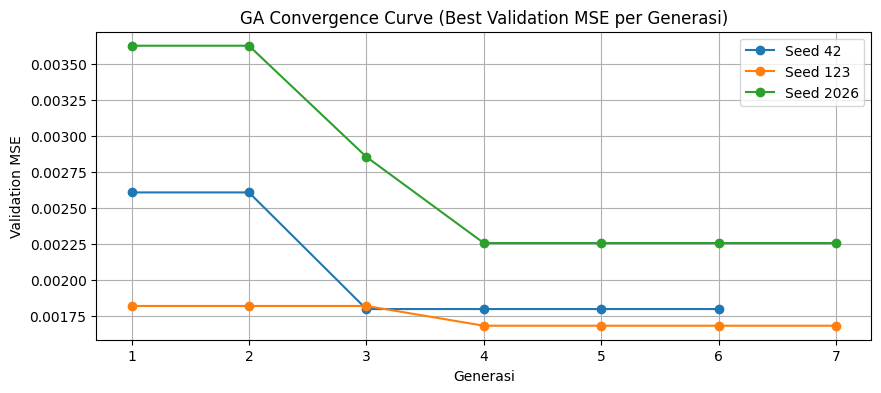

,Nama Fitur,Bit,Status
0,Temperature,1,Terpilih
1,Humidity,0,Dieliminasi
2,Wind Speed,0,Dieliminasi
3,general diffuse flows,0,Dieliminasi
4,diffuse flows,1,Terpilih
5,Hour_sin,0,Dieliminasi
6,Hour_cos,1,Terpilih
7,DayOfWeek_sin,1,Terpilih
8,DayOfWeek_cos,1,Terpilih
9,Z1_Lag_1,0,Dieliminasi


In [ ]:
import matplotlib.pyplot as plt

SEEDS = [42, 123, 2026]
all_logs, seed_results = [], {}

for s in SEEDS:
    b_chrom, b_fit, b_mse, df_log = run_ga(seed=s)
    all_logs.append(df_log)
    seed_results[s] = {"chrom": b_chrom, "fit": b_fit, "mse": b_mse}

df_convergence = pd.concat(all_logs, ignore_index=True)
df_convergence.to_csv("ga_log_konvergensi.csv", index=False)

best_seed = max(seed_results, key=lambda k: seed_results[k]["fit"])
best_overall_chromosome = seed_results[best_seed]["chrom"]
selected_features_ga = [all_feature_cols[i] for i, bit in enumerate(best_overall_chromosome) if bit == 1]

print(f"\n=== Hasil Seleksi Multi-Seed Selesai (Terbaik: Seed {best_seed}) ===")
print(f"Kromosom Terbaik: {best_overall_chromosome}")
print(f"Fitur Terpilih GA ({len(selected_features_ga)} dari 18): {selected_features_ga}")

# Plot Convergence Curve Multi-Seed
plt.figure(figsize=(10, 4))
for s in SEEDS:
    sub = df_convergence[df_convergence["Seed"] == s]
    plt.plot(sub["Generasi"], sub["Best_Val_MSE"], marker='o', label=f"Seed {s}")
plt.title("GA Convergence Curve (Best Validation MSE per Generasi)")
plt.xlabel("Generasi")
plt.ylabel("Validation MSE")
plt.legend()
plt.grid(True)
plt.savefig("ga_convergence_curve.png", dpi=300)
plt.show()

# Tabel Fitur Sebelum vs Sesudah GA
df_features_table = pd.DataFrame({
    "Nama Fitur": all_feature_cols,
    "Bit": best_overall_chromosome,
    "Status": ["Terpilih" if b == 1 else "Dieliminasi" for b in best_overall_chromosome]
})
df_features_table.to_csv("ga_fitur_sebelum_sesudah.csv", index=False)
display(df_features_table)


=== Memulai Algoritma Genetika (Seed = 42) ===
Gen 01/8 | Best Fit: 268.8832 | Avg Fit: 140.3299 | Best Val MSE: 0.00261 | Fitur: 10/18
Gen 02/8 | Best Fit: 268.8832 | Avg Fit: 150.4822 | Best Val MSE: 0.00261 | Fitur: 10/18
Gen 03/8 | Best Fit: 343.5470 | Avg Fit: 183.7312 | Best Val MSE: 0.00180 | Fitur: 10/18
Gen 04/8 | Best Fit: 343.5470 | Avg Fit: 206.0575 | Best Val MSE: 0.00180 | Fitur: 10/18
Gen 05/8 | Best Fit: 343.5470 | Avg Fit: 218.8002 | Best Val MSE: 0.00180 | Fitur: 10/18
Gen 06/8 | Best Fit: 343.5470 | Avg Fit: 226.0714 | Best Val MSE: 0.00180 | Fitur: 10/18
-> Stopping criterion tercapai pada generasi 6.

=== Memulai Algoritma Genetika (Seed = 123) ===
Gen 01/8 | Best Fit: 296.1459 | Avg Fit: 152.2514 | Best Val MSE: 0.00182 | Fitur: 14/18
Gen 02/8 | Best Fit: 296.1459 | Avg Fit: 202.6415 | Best Val MSE: 0.00182 | Fitur: 14/18
Gen 03/8 | Best Fit: 296.1459 | Avg Fit: 221.5103 | Best Val MSE: 0.00182 | Fitur: 14/18
Gen 04/8 | Best Fit: 319.6310 | Avg Fit: 220.4015 | Be

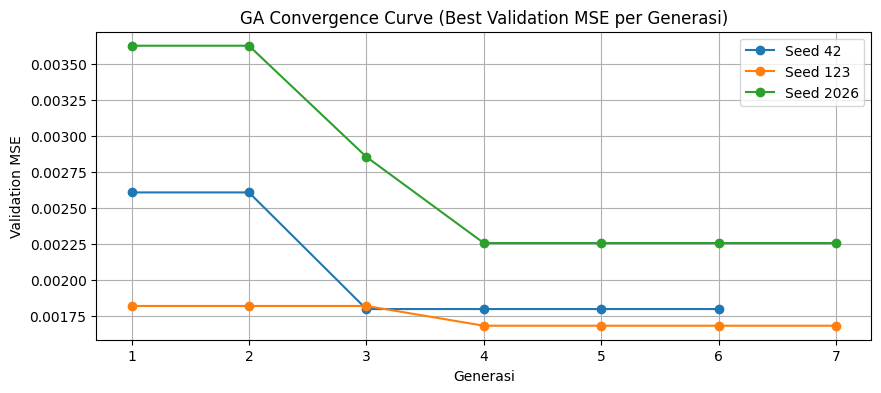

,Nama Fitur,Bit,Status
0,Temperature,1,Terpilih
1,Humidity,0,Dieliminasi
2,Wind Speed,0,Dieliminasi
3,general diffuse flows,0,Dieliminasi
4,diffuse flows,1,Terpilih
5,Hour_sin,0,Dieliminasi
6,Hour_cos,1,Terpilih
7,DayOfWeek_sin,1,Terpilih
8,DayOfWeek_cos,1,Terpilih
9,Z1_Lag_1,0,Dieliminasi


In [ ]:
SEEDS = [42, 123, 2026]
all_logs, seed_results = [], {}

for s in SEEDS:
    b_chrom, b_fit, b_mse, df_log = run_ga(seed=s)
    all_logs.append(df_log)
    seed_results[s] = {"chrom": b_chrom, "fit": b_fit, "mse": b_mse}

df_convergence = pd.concat(all_logs, ignore_index=True)
df_convergence.to_csv("ga_log_konvergensi.csv", index=False)

best_seed = max(seed_results, key=lambda k: seed_results[k]["fit"])
best_overall_chromosome = seed_results[best_seed]["chrom"]
selected_features_ga = [all_feature_cols[i] for i, bit in enumerate(best_overall_chromosome) if bit == 1]

print(f"\n=== Hasil Seleksi Multi-Seed Selesai (Terbaik: Seed {best_seed}) ===")
print(f"Kromosom Terbaik: {best_overall_chromosome}")
print(f"Fitur Terpilih GA ({len(selected_features_ga)} dari 18): {selected_features_ga}")

# Plot Convergence Curve Multi-Seed
plt.figure(figsize=(10, 4))
for s in SEEDS:
    sub = df_convergence[df_convergence["Seed"] == s]
    plt.plot(sub["Generasi"], sub["Best_Val_MSE"], marker='o', label=f"Seed {s}")
plt.title("GA Convergence Curve (Best Validation MSE per Generasi)")
plt.xlabel("Generasi")
plt.ylabel("Validation MSE")
plt.legend()
plt.grid(True)
plt.savefig("ga_convergence_curve.png", dpi=300)
plt.show()

# Tabel Fitur Sebelum vs Sesudah GA
df_features_table = pd.DataFrame({
    "Nama Fitur": all_feature_cols,
    "Bit": best_overall_chromosome,
    "Status": ["Terpilih" if b == 1 else "Dieliminasi" for b in best_overall_chromosome]
})
df_features_table.to_csv("ga_fitur_sebelum_sesudah.csv", index=False)
display(df_features_table)

In [ ]:
selected_idx = [i for i, bit in enumerate(best_overall_chromosome) if bit == 1]

X_tr_B_seq, y_tr_B_seq = create_sequences(X_ga_train_all[:, selected_idx], y_ga_train_all, SEQ_LEN)
X_va_B_seq, y_va_B_seq = create_sequences(X_ga_val_all[:, selected_idx], y_ga_val_all, SEQ_LEN)
X_te_B_seq, y_te_B_seq = create_sequences(X_ga_test_all[:, selected_idx], y_ga_test_all, SEQ_LEN)

train_loader_B = DataLoader(TensorDataset(torch.tensor(X_tr_B_seq, dtype=torch.float32),
                                          torch.tensor(y_tr_B_seq, dtype=torch.float32)), batch_size=64, shuffle=False)
val_loader_B   = DataLoader(TensorDataset(torch.tensor(X_va_B_seq, dtype=torch.float32),
                                          torch.tensor(y_va_B_seq, dtype=torch.float32)), batch_size=64, shuffle=False)
test_loader_B  = DataLoader(TensorDataset(torch.tensor(X_te_B_seq, dtype=torch.float32),
                                          torch.tensor(y_te_B_seq, dtype=torch.float32)), batch_size=64, shuffle=False)

torch.manual_seed(best_seed)
model_B = BaselineRNN(input_dim=len(selected_idx), hidden_dim=64, output_dim=3).to(device)
criterion_B = nn.MSELoss()
optimizer_B = torch.optim.Adam(model_B.parameters(), lr=0.001)

epochs = 5
print("--- Memulai Pelatihan Model B (GA + RNN) ---")
start_time_B = time.time()

for epoch in range(epochs):
    model_B.train()
    train_loss = 0
    for X_b, y_b in train_loader_B:
        X_b, y_b = X_b.to(device), y_b.to(device)
        optimizer_B.zero_grad()
        preds = model_B(X_b)
        loss = criterion_B(preds, y_b)
        loss.backward()
        optimizer_B.step()
        train_loss += loss.item()

    val_mse_B, val_rmse_B, val_mae_B, val_r2_B = evaluate_metrics(model_B, val_loader_B, scaler_y_ga)
    print(f"Epoch {epoch+1:02d}/{epochs} | Train MSE: {train_loss/len(train_loader_B):.5f} | Val MSE: {val_mse_B:.5f} | Val RMSE: {val_rmse_B:.2f}")

time_B = time.time() - start_time_B
val_mse_B, val_rmse_B, val_mae_B, val_r2_B = evaluate_metrics(model_B, val_loader_B, scaler_y_ga)
test_mse_B, test_rmse_B, test_mae_B, test_r2_B = evaluate_metrics(model_B, test_loader_B, scaler_y_ga)
print(f"Selesai ({time_B:.2f} dtk) | Val RMSE: {val_rmse_B:.2f} | Test RMSE: {test_rmse_B:.2f} | Test R2: {test_r2_B:.4f}")

--- Memulai Pelatihan Model B (GA + RNN) ---
Epoch 01/5 | Train MSE: 0.00752 | Val MSE: 0.00269 | Val RMSE: 1827.47
Epoch 02/5 | Train MSE: 0.00220 | Val MSE: 0.00211 | Val RMSE: 1624.39
Epoch 03/5 | Train MSE: 0.00180 | Val MSE: 0.00373 | Val RMSE: 2123.93
Epoch 04/5 | Train MSE: 0.00213 | Val MSE: 0.00295 | Val RMSE: 1947.91
Epoch 05/5 | Train MSE: 0.00168 | Val MSE: 0.00173 | Val RMSE: 1510.03
Selesai (73.58 dtk) | Val RMSE: 1510.03 | Test RMSE: 2277.36 | Test R2: 0.8144


In [ ]:
import json

df_summary = pd.DataFrame({
    "Model": ["Model A (Baseline RNN)", "Model B (GA + RNN)"],
    "Jumlah Fitur": [len(feature_cols), len(selected_features_ga)],
    "Val MSE": [round(val_mse_A, 5), round(val_mse_B, 5)],
    "Val RMSE (kW)": [round(val_rmse_A, 2), round(val_rmse_B, 2)],
    "Val MAE (kW)": [round(val_mae_A, 2), round(val_mae_B, 2)],
    "Val R2": [round(val_r2_A, 4), round(val_r2_B, 4)],
    "Test RMSE (kW)": [round(test_rmse_A, 2), round(test_rmse_B, 2)],
    "Test R2": [round(test_r2_A, 4), round(test_r2_B, 4)],
    "Waktu Komputasi (detik)": [round(time_A, 2), round(time_B, 2)]
})

print("=== TABEL EVALUASI PEMBANDING BASELINE RNN VS GA+RNN ===")
display(df_summary)
df_summary.to_csv("ga_perbandingan_model.csv", index=False)

# Simpan bobot model & JSON fitur terpilih untuk Dashboard Streamlit
torch.save(model_B.state_dict(), "ga_rnn.pth")
with open("ga_selected_features.json", "w") as f:
    json.dump({"best_seed": int(best_seed), "selected_features": selected_features_ga,
               "chromosome": best_overall_chromosome.tolist()}, f, indent=2)

=== TABEL EVALUASI PEMBANDING BASELINE RNN VS GA+RNN ===


,Model,Jumlah Fitur,Val MSE,Val RMSE (kW),Val MAE (kW),Val R2,Test RMSE (kW),Test R2,Waktu Komputasi (detik)
0,Model A (Baseline RNN),9,0.00717,2990.07,2410.04,0.5422,4904.75,-0.0680,76.78
1,Model B (GA + RNN),10,0.00173,1510.03,1097.96,0.9189,2277.36,0.8144,73.58


In [ ]:
import zipfile
from google.colab import files

daftar_file = [
    "ga_convergence_curve.png",
    "ga_log_konvergensi.csv",
    "ga_fitur_sebelum_sesudah.csv",
    "ga_perbandingan_model.csv",
    "ga_selected_features.json",
    "ga_rnn.pth"
]

with zipfile.ZipFile("Hasil_GA_RNN.zip", "w") as zipf:
    for f in daftar_file:
        zipf.write(f)

files.download("Hasil_GA_RNN.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>